<a href="https://colab.research.google.com/github/blmvv/MachineLearning/blob/Machine-Learning/%D0%9B%D0%A0_10_%D0%9C%D0%9D_%D0%9A%D0%B5%D1%80%D0%B0%D1%81_%D0%91%D1%96%D0%BB%D0%B8%D0%BC.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота № 10
## Побудова нейронної мережі засобами Keras. Налаштування гіперпараметрів

**Дисципліна:** Машинне навчання  
**Прізвище, ім’я:** Білим Вадим  
**Група:** ФІТ 4-10  
**Дата:** 26.11.2026

**Мета:** навчитися завантажувати та готувати дані Fashion MNIST, створювати і навчати нейронну мережу засобами Keras, оцінювати якість класифікації, а також підбирати гіперпараметри за допомогою Keras Tuner.

**Порядок виконання:** послідовно виконайте кожен пункт у наведених комірках. Доповніть код, збережіть графіки та результати виконання, сформулюйте власні висновки.

### Вхідні дані та критерії

Використовуйте **Fashion MNIST** — зображення розміром **28 × 28 пікселів** із **10 класів**.  
У **завданні 1** цільова точність на тестовій вибірці — **не нижче 0,87** (відповідно до вихідної лабораторної роботи).

**Важливо:** тестова вибірка призначена для фінального оцінювання. Для навчання, ранньої зупинки та добору гіперпараметрів використовуйте окрему валідаційну частину навчальних даних; не налаштовуйте модель за результатами тестової вибірки.

## Підготовка робочого середовища

Імпортуйте необхідні бібліотеки. У другому завданні буде потрібно встановити та підключити **Keras Tuner**.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report

from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


# Завдання 1. Класифікація Fashion MNIST за допомогою Keras

### Крок 1. Завантаження даних

Завантажте Fashion MNIST. Створіть навчальну й тестову вибірки та перелік назв **10 класів**. Виведіть розміри масивів даних.

In [ ]:
(x_train, y_train), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()

class_names = [
    'Футболка', 'Штани', 'Светр', 'Сукня', 'Пальто',
    'Сандалі', 'Сорочка', 'Кросівки', 'Сумка', 'Черевики']

print("x_train:", x_train.shape)
print("y_train:", y_train.shape)
print("x_test:", x_test.shape)
print("y_test:", y_test.shape)

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
x_train: (60000, 28, 28)
y_train: (60000,)
x_test: (10000, 28, 28)
y_test: (10000,)


### Крок 2. Візуальний аналіз

Виведіть **10 зображень** навчальної вибірки. Для кожного підпишіть відповідний клас.

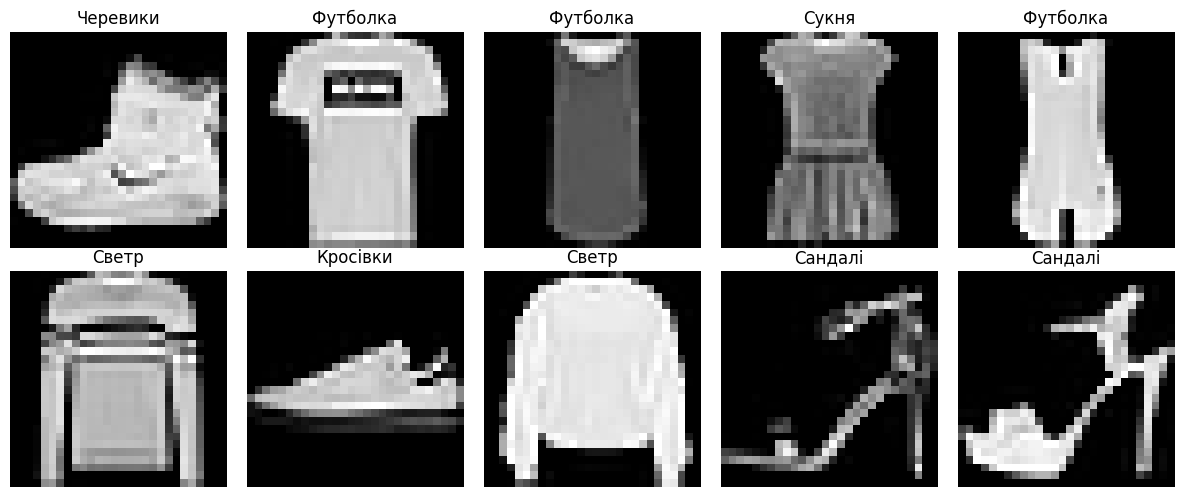

In [ ]:
plt.figure(figsize=(12, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap='gray')
    plt.title(class_names[y_train[i]])
    plt.axis('off')

plt.tight_layout()
plt.show()

### Крок 3. Нормалізація

Нормалізуйте значення пікселів до діапазону **[0; 1]**. Переконайтеся, що тип даних придатний для навчання нейронної мережі.

In [ ]:
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

print("Мінімальне значення:", x_train.min())
print("Максимальне значення:", x_train.max())
print("Тип даних:", x_train.dtype)

Мінімальне значення: 0.0
Максимальне значення: 1.0
Тип даних: float32


### Крок 4. Побудова й компіляція моделі

Створіть послідовну нейронну мережу. Використайте перетворення зображення у вектор, повнозв’язні шари з **ReLU**, регуляризацію **Dropout** та вихід із **10 нейронів із softmax**. Налаштуйте оптимізатор Adam, функцію втрат для багатокласової класифікації з цілочисельними мітками та метрику accuracy.

Поясніть вибір кількості нейронів, dropout і швидкості навчання.

In [ ]:
model = keras.Sequential([
    layers.Flatten(input_shape=(28, 28)),

    layers.Dense(256, activation='relu'),
    layers.Dropout(0.3),

    layers.Dense(128, activation='relu'),
    layers.Dropout(0.2),

    layers.Dense(10, activation='softmax')])

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy'])

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 235,146 (918.54 KB)

 Trainable params: 235,146 (918.54 KB)

 Non-trainable params: 0 (0.00 B)

### Крок 5. Навчання моделі

Навчіть модель із виділенням **валідаційної частини з навчальної вибірки**. Застосуйте **EarlyStopping** і **ReduceLROnPlateau**. Збережіть історію навчання для подальших графіків.

In [ ]:
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True)

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=2,
    min_lr=0.00001)

history = model.fit(
    x_train,
    y_train,
    epochs=30,
    batch_size=64,
    validation_split=0.2,
    callbacks=[early_stopping, reduce_lr],
    verbose=1)

Epoch 1/30
750/750 ━━━━━━━━━━━━━━━━━━━━ 9s 11ms/step - accuracy: 0.7892 - loss: 0.5917 - val_accuracy: 0.8370 - val_loss: 0.4485 - learning_rate: 0.0010
Epoch 2/30
750/750 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.8414 - loss: 0.4333 - val_accuracy: 0.8651 - val_loss: 0.3724 - learning_rate: 0.0010
Epoch 3/30
750/750 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.8547 - loss: 0.3947 - val_accuracy: 0.8678 - val_loss: 0.3640 - learning_rate: 0.0010
Epoch 4/30
750/750 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.8639 - loss: 0.3724 - val_accuracy: 0.8683 - val_loss: 0.3537 - learning_rate: 0.0010
Epoch 5/30
750/750 ━━━━━━━━━━━━━━━━━━━━ 7s 10ms/step - accuracy: 0.8689 - loss: 0.3551 - val_accuracy: 0.8682 - val_loss: 0.3540 - learning_rate: 0.0010
Epoch 6/30
750/750 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.8739 - loss: 0.3421 - val_accuracy: 0.8801 - val_loss: 0.3313 - learning_rate: 0.0010
Epoch 7/30
750/750 ━━━━━━━━━━━━━━━━━━━━ 13s 18ms/step - accuracy: 0.8782 - loss: 0.32

### Крок 6. Аналіз архітектури

Виведіть підсумкову структуру нейронної мережі, кількість шарів і параметрів.

In [ ]:
model.summary()

print("Кількість шарів:", len(model.layers))
print("Загальна кількість параметрів:", model.count_params())

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 705,440 (2.69 MB)

 Trainable params: 235,146 (918.54 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 470,294 (1.79 MB)

Кількість шарів: 6
Загальна кількість параметрів: 235146


### Крок 7. Збереження моделі

Збережіть навчену модель у форматі **`.keras`**. Під час роботи в Google Colab за потреби підключіть Google Drive.

In [ ]:
model.save('fashion_mnist_model.keras')

print("Модель збережено.")

Модель збережено.


### Крок 8. Графіки навчання

Побудуйте два графіки: **функція втрат (loss)** і **точність (accuracy)** для навчальної та валідаційної вибірок. Підпишіть осі, легенди й назви графіків.

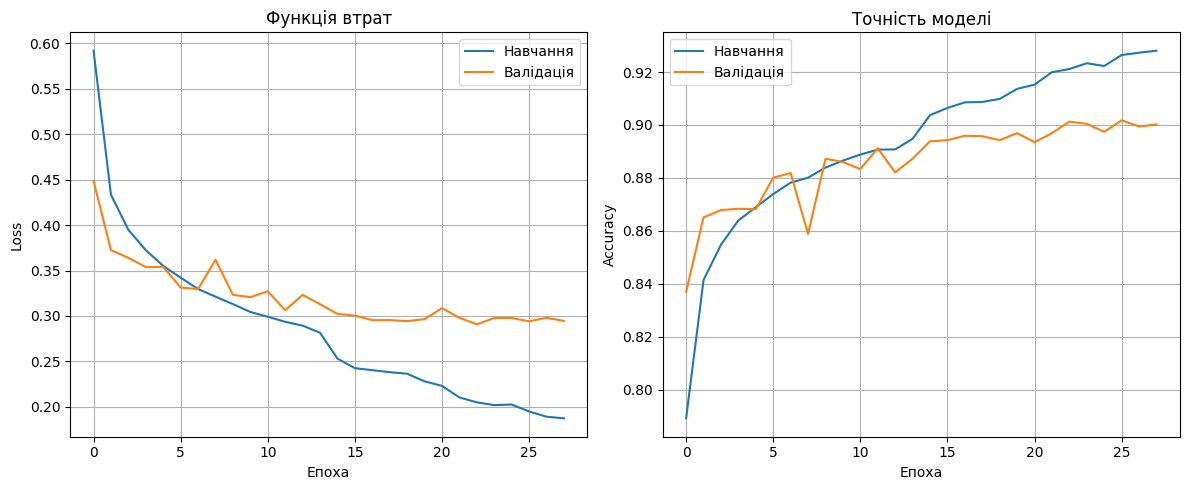

In [ ]:
plt.figure(figsize=(12, 5))

# Графік функції втрат
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Навчання')
plt.plot(history.history['val_loss'], label='Валідація')
plt.title('Функція втрат')
plt.xlabel('Епоха')
plt.ylabel('Loss')
plt.legend()
plt.grid()

# Графік точності
plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Навчання')
plt.plot(history.history['val_accuracy'], label='Валідація')
plt.title('Точність моделі')
plt.xlabel('Епоха')
plt.ylabel('Accuracy')
plt.legend()
plt.grid()

plt.tight_layout()
plt.show()

### Крок 9. Оцінювання моделі

Один раз оцініть навчену модель на **тестовій вибірці**. Отримайте прогнози й сформуйте **класифікаційний звіт** (precision, recall, F1-score) для всіх класів.

Порівняйте отриману accuracy з порогом **0,87**.

In [ ]:
test_loss, test_accuracy = model.evaluate(x_test, y_test, verbose=0)

print("Test loss:", test_loss)
print("Test accuracy:", test_accuracy)
print("Точність у відсотках:", test_accuracy * 100)

y_pred = model.predict(x_test)
y_pred_classes = np.argmax(y_pred, axis=1)

print("\nКласифікаційний звіт:")
print(classification_report(
    y_test,
    y_pred_classes,
    target_names=class_names
))

Test loss: 0.31312796473503113
Test accuracy: 0.8939999938011169
Точність у відсотках: 89.3999993801117
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step

Класифікаційний звіт:
              precision    recall  f1-score   support

    Футболка       0.85      0.85      0.85      1000
       Штани       0.99      0.98      0.98      1000
       Светр       0.83      0.79      0.81      1000
       Сукня       0.91      0.90      0.90      1000
      Пальто       0.79      0.83      0.81      1000
     Сандалі       0.98      0.97      0.98      1000
     Сорочка       0.71      0.73      0.72      1000
    Кросівки       0.94      0.97      0.96      1000
       Сумка       0.98      0.97      0.97      1000
    Черевики       0.97      0.96      0.96      1000

    accuracy                           0.89     10000
   macro avg       0.90      0.89      0.89     10000
weighted avg       0.90      0.89      0.89     10000



### Крок 10. Візуалізація прогнозів

Покажіть **10 тестових зображень**. Для кожного вкажіть правильний і прогнозований клас, а правильність прогнозу позначте кольором підпису.

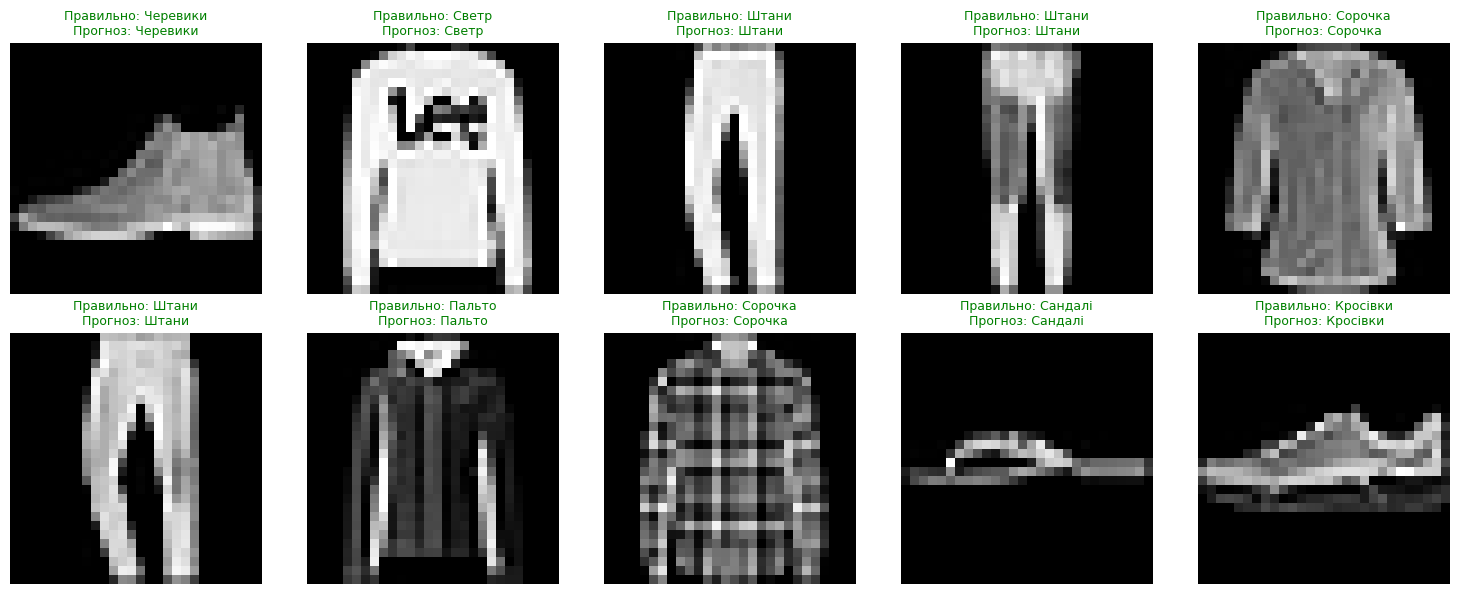

In [ ]:
plt.figure(figsize=(15, 6))

for i in range(10):
    plt.subplot(2, 5, i + 1)

    plt.imshow(x_test[i], cmap='gray')

    true_label = class_names[y_test[i]]
    predicted_label = class_names[y_pred_classes[i]]

    color = 'green' if y_test[i] == y_pred_classes[i] else 'red'

    plt.title(
        f"Правильно: {true_label}\nПрогноз: {predicted_label}",
        color=color,
        fontsize=9
    )

    plt.axis('off')

plt.tight_layout()
plt.show()

**Проміжний висновок до завдання 1**

Запишіть значення тестової accuracy, охарактеризуйте класи з найбільшою кількістю помилок та поясніть, чи виконано вимогу щодо мінімальної точності.

**Ваш висновок:**  
У першому завданні було створено та навчено нейронну мережу для класифікації зображень набору Fashion MNIST. Модель складалася з двох прихованих шарів на 256 та 128 нейронів із функцією активації ReLU та використанням Dropout. Навчання виконувалося за допомогою оптимізатора Adam зі швидкістю навчання 0,001. У результаті модель досягла точності **89,4%** на тестовій вибірці, що перевищує заданий поріг 87%. Отже, створена модель успішно виконує класифікацію зображень одягу.

# Завдання 2. Добір гіперпараметрів за допомогою Keras Tuner

На основі того самого набору даних виконайте автоматизований пошук конфігурації нейронної мережі. У вихідній лабораторній роботі використовується **RandomSearch**.

### Крок 1. Підготовка Keras Tuner

Установіть `keras-tuner` (за потреби) й імпортуйте засоби для пошуку гіперпараметрів, шари Dense, Flatten, Dropout та регуляризацію L2.

In [ ]:
!pip install -q keras-tuner
import keras_tuner as kt

from tensorflow.keras import regularizers
from tensorflow.keras.layers import Dense, Flatten, Dropout

### Крок 2. Підготовка набору даних

Повторно використайте Fashion MNIST у нормалізованому вигляді. Переконайтеся, що вибірка для **валідації відокремлена від тестової**. Не передавайте `x_test`, `y_test` у процес пошуку гіперпараметрів.

In [ ]:
x_train_tuner, x_val_tuner, y_train_tuner, y_val_tuner = train_test_split(
    x_train,
    y_train,
    test_size=0.2,
    random_state=42)

print("Навчальна вибірка:", x_train_tuner.shape)
print("Валідаційна вибірка:", x_val_tuner.shape)
print("Тестова вибірка:", x_test.shape)

Навчальна вибірка: (48000, 28, 28)
Валідаційна вибірка: (12000, 28, 28)
Тестова вибірка: (10000, 28, 28)


### Крок 3. Функція побудови моделі

Реалізуйте функцію, яка приймає набір гіперпараметрів та повертає скомпільовану модель. Передбачте пошук **кількості прихованих шарів (1–3)**, **кількості нейронів (32–512 із кроком 32)** та **швидкості навчання (0,01; 0,001; 0,0001)**. Використайте ReLU, Dropout, L2 та softmax, як у вихідному варіанті лабораторної роботи.

In [ ]:
def build_model(hp):
    model = keras.Sequential()

    model.add(Flatten(input_shape=(28, 28)))

    # Кількість прихованих шарів
    num_layers = hp.Int('num_layers', min_value=1, max_value=3)

    # Додавання прихованих шарів
    for i in range(num_layers):
        units = hp.Int(
            f'units_{i}',
            min_value=32,
            max_value=512,
            step=32)

        model.add(Dense(
            units,
            activation='relu',
            kernel_regularizer=regularizers.l2(0.001)))

        model.add(Dropout(0.2))

    # Вихідний шар
    model.add(Dense(10, activation='softmax'))

    # Підбір швидкості навчання
    learning_rate = hp.Choice(
        'learning_rate',
        values=[0.01, 0.001, 0.0001])

    model.compile(
        optimizer=keras.optimizers.Adam(
            learning_rate=learning_rate
        ),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy'])

    return model

### Крок 4. Налаштування пошуку

Створіть **RandomSearch** з критерієм **val_accuracy**. У вихідному прикладі передбачено **3 спроби (max_trials = 3)** і **1 виконання на спробу**. Зазначте каталог збереження результатів пошуку.

In [ ]:
tuner = kt.RandomSearch(
    build_model,
    objective='val_accuracy',
    max_trials=3,
    executions_per_trial=1,
    directory='keras_tuner_results',
    project_name='fashion_mnist')

tuner.search_space_summary()

Search space summary
Default search space size: 3
num_layers (Int)
{'default': None, 'conditions': [], 'min_value': 1, 'max_value': 3, 'step': 1, 'sampling': 'linear'}
units_0 (Int)
{'default': None, 'conditions': [], 'min_value': 32, 'max_value': 512, 'step': 32, 'sampling': 'linear'}
learning_rate (Choice)
{'default': 0.01, 'conditions': [], 'values': [0.01, 0.001, 0.0001], 'ordered': True}


/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


### Крок 5. Пошук та вибір найкращої конфігурації

Запустіть пошук із **EarlyStopping** і **ReduceLROnPlateau**, використовуючи лише навчальні та валідаційні дані. Виведіть знайдені гіперпараметри та структуру найкращої моделі. За потреби перенавчіть обрану конфігурацію, зберігши історію навчання.

In [ ]:
tuner.search(
    x_train_tuner,
    y_train_tuner,
    epochs=20,
    validation_data=(x_val_tuner, y_val_tuner),
    callbacks=[
        EarlyStopping(
            monitor='val_loss',
            patience=4,
            restore_best_weights=True),
        ReduceLROnPlateau(
            monitor='val_loss',
            factor=0.5,
            patience=2,
            min_lr=0.00001)],
    verbose=1)

Trial 3 Complete [00h 05m 01s]
val_accuracy: 0.8371666669845581

Best val_accuracy So Far: 0.8856666684150696
Total elapsed time: 00h 13m 16s


In [ ]:
best_hp = tuner.get_best_hyperparameters(num_trials=1)[0]

print("Найкращі параметри:")
print("Кількість прихованих шарів:", best_hp.get('num_layers'))

for i in range(best_hp.get('num_layers')):
    print(f"Нейронів у шарі {i + 1}:", best_hp.get(f'units_{i}'))

print("Швидкість навчання:", best_hp.get('learning_rate'))

Найкращі параметри:
Кількість прихованих шарів: 2
Нейронів у шарі 1: 256
Нейронів у шарі 2: 32
Швидкість навчання: 0.001


In [ ]:
best_model = tuner.get_best_models(num_models=1)[0]

best_model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 14 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         8,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 209,514 (818.41 KB)

 Trainable params: 209,514 (818.41 KB)

 Non-trainable params: 0 (0.00 B)

### Крок 6. Фінальне оцінювання та графіки

Оцініть найкращу модель на **тестовій вибірці**. Наведіть тестові loss і accuracy. Побудуйте графіки навчальної/валідаційної функції втрат і точності.

In [ ]:
final_model = tuner.hypermodel.build(best_hp)

history_tuner = final_model.fit(
    x_train_tuner,
    y_train_tuner,
    epochs=20,
    batch_size=64,
    validation_data=(x_val_tuner, y_val_tuner),
    callbacks=[
        EarlyStopping(
            monitor='val_loss',
            patience=5,
            restore_best_weights=True
        ),
        ReduceLROnPlateau(
            monitor='val_loss',
            factor=0.5,
            patience=2,
            min_lr=0.00001
        )
    ],
    verbose=1
)

Epoch 1/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 8s 9ms/step - accuracy: 0.7654 - loss: 0.9151 - val_accuracy: 0.8394 - val_loss: 0.6279 - learning_rate: 0.0010
Epoch 2/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.8268 - loss: 0.6447 - val_accuracy: 0.8471 - val_loss: 0.5512 - learning_rate: 0.0010
Epoch 3/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - accuracy: 0.8359 - loss: 0.5898 - val_accuracy: 0.8487 - val_loss: 0.5436 - learning_rate: 0.0010
Epoch 4/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.8414 - loss: 0.5617 - val_accuracy: 0.8492 - val_loss: 0.5347 - learning_rate: 0.0010
Epoch 5/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - accuracy: 0.8461 - loss: 0.5462 - val_accuracy: 0.8429 - val_loss: 0.5297 - learning_rate: 0.0010
Epoch 6/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 8s 7ms/step - accuracy: 0.8472 - loss: 0.5390 - val_accuracy: 0.8606 - val_loss: 0.4846 - learning_rate: 0.0010
Epoch 7/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - accuracy: 0.8475 - loss: 0.5319 - 

In [ ]:
best_hp = tuner.get_best_hyperparameters(num_trials=1)[0]

print("Найкращі параметри:")
print("Кількість прихованих шарів:", best_hp.get('num_layers'))

for i in range(best_hp.get('num_layers')):
    print(f"Нейронів у шарі {i + 1}:", best_hp.get(f'units_{i}'))

print("Швидкість навчання:", best_hp.get('learning_rate'))

Найкращі параметри:
Кількість прихованих шарів: 2
Нейронів у шарі 1: 256
Нейронів у шарі 2: 32
Швидкість навчання: 0.001


In [ ]:
best_model = tuner.get_best_models(num_models=1)[0]

best_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         8,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 209,514 (818.41 KB)

 Trainable params: 209,514 (818.41 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
final_model = tuner.hypermodel.build(best_hp)

history_tuner = final_model.fit(
    x_train_tuner,
    y_train_tuner,
    epochs=20,
    batch_size=64,
    validation_data=(x_val_tuner, y_val_tuner),
    callbacks=[
        EarlyStopping(
            monitor='val_loss',
            patience=5,
            restore_best_weights=True
        ),
        ReduceLROnPlateau(
            monitor='val_loss',
            factor=0.5,
            patience=2,
            min_lr=0.00001
        )
    ],
    verbose=1
)

Epoch 1/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 9s 9ms/step - accuracy: 0.7699 - loss: 0.9180 - val_accuracy: 0.8355 - val_loss: 0.6366 - learning_rate: 0.0010
Epoch 2/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.8262 - loss: 0.6508 - val_accuracy: 0.8210 - val_loss: 0.6225 - learning_rate: 0.0010
Epoch 3/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 7s 10ms/step - accuracy: 0.8357 - loss: 0.5961 - val_accuracy: 0.8466 - val_loss: 0.5407 - learning_rate: 0.0010
Epoch 4/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.8425 - loss: 0.5636 - val_accuracy: 0.8466 - val_loss: 0.5307 - learning_rate: 0.0010
Epoch 5/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.8454 - loss: 0.5533 - val_accuracy: 0.8572 - val_loss: 0.5119 - learning_rate: 0.0010
Epoch 6/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.8466 - loss: 0.5396 - val_accuracy: 0.8501 - val_loss: 0.5149 - learning_rate: 0.0010
Epoch 7/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 11s 14ms/step - accuracy: 0.8484 - loss: 0.535

In [ ]:
tuner_test_loss, tuner_test_accuracy = final_model.evaluate(
    x_test, y_test, verbose=0
)

print("Test loss:", tuner_test_loss)
print("Test accuracy:", tuner_test_accuracy)
print("Точність у відсотках:", tuner_test_accuracy * 100)

Test loss: 0.4250699579715729
Test accuracy: 0.8738999962806702
Точність у відсотках: 87.38999962806702


In [ ]:
y_pred_tuner = final_model.predict(x_test)

y_pred_tuner_classes = np.argmax(y_pred_tuner, axis=1)

print(classification_report(
    y_test,
    y_pred_tuner_classes,
    target_names=class_names
))

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
              precision    recall  f1-score   support

    Футболка       0.84      0.81      0.83      1000
       Штани       0.99      0.97      0.98      1000
       Светр       0.74      0.83      0.78      1000
       Сукня       0.89      0.89      0.89      1000
      Пальто       0.81      0.75      0.78      1000
     Сандалі       0.94      0.97      0.96      1000
     Сорочка       0.67      0.67      0.67      1000
    Кросівки       0.94      0.95      0.94      1000
       Сумка       0.97      0.96      0.97      1000
    Черевики       0.96      0.93      0.95      1000

    accuracy                           0.87     10000
   macro avg       0.88      0.87      0.87     10000
weighted avg       0.88      0.87      0.87     10000



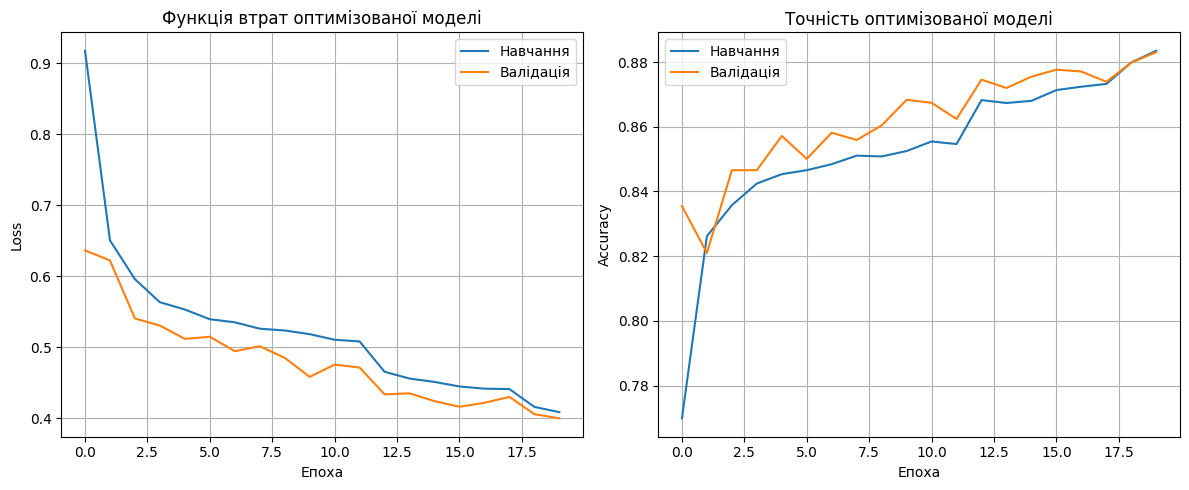

In [ ]:
plt.figure(figsize=(12, 5))

# Функція втрат
plt.subplot(1, 2, 1)
plt.plot(history_tuner.history['loss'], label='Навчання')
plt.plot(history_tuner.history['val_loss'], label='Валідація')
plt.title('Функція втрат оптимізованої моделі')
plt.xlabel('Епоха')
plt.ylabel('Loss')
plt.legend()
plt.grid()

# Точність
plt.subplot(1, 2, 2)
plt.plot(history_tuner.history['accuracy'], label='Навчання')
plt.plot(history_tuner.history['val_accuracy'], label='Валідація')
plt.title('Точність оптимізованої моделі')
plt.xlabel('Епоха')
plt.ylabel('Accuracy')
plt.legend()
plt.grid()

plt.tight_layout()
plt.show()

# Висновки. Порівняння моделей

Порівняйте модель із завдання 1 та модель після автоматизованого налаштування. Результати внесіть до таблиці.

| Показник | Модель із завдання 1 | Модель після Keras Tuner |
|---|---|---|
| Кількість прихованих шарів | 2 | 2 |
| Кількість нейронів | 256; 128 | 256; 32 |
| Швидкість навчання | 0,001 | 0,001 |
| Точність на тестовій вибірці (accuracy) | 89,4 | 87,4 |
| Втрати на тестовій вибірці (loss) | 0,31 | 0,42 |
| Кількість епох навчання | 28 | 20 |

**Власні висновки:**  
У лабораторній роботі було розглянуто створення, навчання та налаштування нейронних мереж засобами Keras. Було використано набір даних Fashion MNIST, виконано нормалізацію зображень, створено нейронну мережу та проведено її навчання. Перша модель досягла точності 89,4% на тестовій вибірці, що перевищує заданий поріг 87%. Також було виконано автоматичний підбір гіперпараметрів за допомогою Keras Tuner. Найкраща конфігурація містила два приховані шари на 256 та 32 нейрони. У результаті роботи було отримано практичні навички створення, навчання, оцінювання та оптимізації нейронних мереж, а також досліджено вплив гіперпараметрів на якість класифікації зображень.